<a href="https://colab.research.google.com/github/bcntp5/Complete-Python-3-Bootcamp/blob/master/End_to_End_Machine_Learning_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# An End-to-End Machine Learning Project

This notebook demonstrates an example of an end-to-end machine learning project. You will be instroduced to the following steps:
- Preliminary analysis
- Data preprocessing
- Model training and tuning
- Model selection

## The Problem

Model the attrition of healthcare employees (whether they left or not) based on information including the employees' general information and their working information. The columns in the data are as follows

- EmployeeID
- Age
- **Attrition**
- BusinessTravel
- DailyRate
- Department
- DistanceFromHome
- Education
- EducationField
- EnvironmentSatisfaction
- Gender
- HourlyRate
- JobInvolvement
- JobLevel
- JobRole
- JobSatisfaction
- MaritalStatus
- MonthlyIncome
- MonthlyRate
- NumCompaniesWorked
- Over18
- OverTime
- PercentSalaryHike
- PerformanceRating
- RelationshipSatisfaction
- StandardHours
- Shift
- TotalWorkingYears
- TrainingTimesLastYear
- WorkLifeBalance
- YearsAtCompany
- YearsInCurrentRole
- YearsSinceLastPromotion
- YearsWithCurrManager

## Loading the Data

This data is a typical csv file with headers. We can use the default settings of `read_csv()`. We can then use `head()` to examine the data.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

attr = pd.read_csv('/content/drive/MyDrive/IT7103/Module4/attrition.csv')
attr.head()

Mounted at /content/drive


,EmployeeID,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,...,RelationshipSatisfaction,StandardHours,Shift,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1313919,41.0,No,Travel_Rarely,1102.0,Cardiology,1.0,2.0,Life Sciences,2.0,...,1.0,80.0,NaN,8.0,0.0,1.0,6.0,4.0,0.0,5.0
1,1200302,49.0,No,Travel_Frequently,279.0,Maternity,8.0,1.0,Life Sciences,3.0,...,4.0,80.0,1.0,10.0,3.0,3.0,10.0,7.0,1.0,7.0
2,1060315,37.0,Yes,Travel_Rarely,1373.0,Maternity,2.0,NaN,Other,4.0,...,2.0,80.0,0.0,7.0,3.0,3.0,0.0,0.0,0.0,0.0
3,1272912,33.0,No,Travel_Frequently,1392.0,Maternity,3.0,4.0,Life Sciences,4.0,...,3.0,80.0,0.0,8.0,3.0,3.0,8.0,7.0,3.0,0.0
4,1414939,27.0,No,Travel_Rarely,591.0,Maternity,2.0,1.0,Medical,1.0,...,4.0,80.0,1.0,NaN,3.0,3.0,2.0,NaN,NaN,2.0


As discuss, the `shape` attribute quickly shows the number of rows and columns of the dataframe

In [ ]:
attr.shape

(1676, 34)

## First Look into the Data

As previously mentioned, we can use `dtypes` for a list of each column's data type. Another similar method that provides more information is `DataFrame.info()` which will give the number of rows and columns, non-null count (non-missing) and column types.

Take note on the non-null count; any column with a non-null count less than the total number of rows in the dataset means it has missing values that we must handle later on.

Our target in this data is **Attrition**

In [2]:
attr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1676 entries, 0 to 1675
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeID                1676 non-null   int64  
 1   Age                       1508 non-null   float64
 2   Attrition                 1676 non-null   object 
 3   BusinessTravel            1676 non-null   object 
 4   DailyRate                 1508 non-null   float64
 5   Department                1676 non-null   object 
 6   DistanceFromHome          1508 non-null   float64
 7   Education                 1508 non-null   float64
 8   EducationField            1676 non-null   object 
 9   EnvironmentSatisfaction   1508 non-null   float64
 10  Gender                    1676 non-null   object 
 11  HourlyRate                1508 non-null   float64
 12  JobInvolvement            1508 non-null   float64
 13  JobLevel                  1508 non-null   float64
 14  JobRole 

Based on the results from `info()`, the majority of the columns are considered numeric (indicated by the `int64` or `float64` type). Attrition, BusinessTravel, Department, EducationField, Gender, JobRole, MaritalStatus, Over18 and OverTime are considered class (indicated by the object type).

Did this data get loaded in correctly?


# Train-Test Split

A quick look into the data is all you should done before train/test splitting.

As we mentioned in the first module, a machine learning model is usually trained to work on future unknown data. For this reason, we need some measurements that are able to reflect its performance on unknown data instead of the data the model is trained on. This leads to train/test splitting -- we split the dataset we have into a training set for model training, and a testing set that will be kept untouch until we have finalized and trained models.

This means, every steps from now, including visualization and processing, are performed in the training set. The testing set will be kept untouch until we are ready to evaluate our models.

There are different ways of splitting a data. In this example, we will do random split. We will use `train_test_split()` from `scikit-learn` for this action. We need to provide the input dataset, and the ratio of `training:testing` sizes. Let's note their number of rows since they are important information

In [3]:
from sklearn.model_selection import train_test_split

traindata, testdata = train_test_split(attr, test_size=0.2) #test_size=0.2 means that 20% of data will be for testing, 80% for training
traindata.shape, testdata.shape

((1340, 34), (336, 34))

## Preliminary Analysis

Now, we can investigate the training data for more insights. In this step, we can utilize different statistics and charts to summarize information.

For statistics, we use `describe()`. We can see all the numeric columns have some **missing values** which is indicated by the count being less than the training data size.

Later one, we have to deal with missing values through a process called **imputation**.

In [ ]:
traindata.describe()

,EmployeeID,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,RelationshipSatisfaction,StandardHours,Shift,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1.340000e+03,1212.000000,1210.000000,1211.000000,1204.000000,1203.000000,1204.000000,1200.000000,1202.000000,1211.000000,...,1207.000000,1203.0,1211.000000,1206.000000,1204.000000,1205.000000,1210.000000,1199.000000,1198.000000,1201.000000
mean,1.457565e+06,36.915842,812.377686,9.094137,2.906977,2.704904,65.803987,2.739167,2.059068,2.734930,...,2.717481,80.0,0.800991,11.384743,2.818937,2.765975,7.050413,4.240200,2.197830,4.164030
std,2.485628e+05,9.185375,404.888287,8.063450,1.017544,1.114211,20.230092,0.717562,1.120844,1.111143,...,1.074606,0.0,0.843565,7.950024,1.285681,0.709455,6.149901,3.643186,3.276727,3.556764
min,1.025177e+06,18.000000,102.000000,1.000000,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.238722e+06,30.000000,471.000000,2.000000,2.000000,2.000000,48.000000,2.000000,1.000000,2.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,1.460774e+06,36.000000,810.000000,7.000000,3.000000,3.000000,66.000000,3.000000,2.000000,3.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,1.668417e+06,43.000000,1180.000000,13.000000,4.000000,4.000000,83.000000,3.000000,3.000000,4.000000,...,4.000000,80.0,1.000000,15.750000,3.000000,3.000000,10.000000,7.000000,3.000000,7.000000
max,1.886378e+06,60.000000,1499.000000,29.000000,5.000000,4.000000,100.000000,4.000000,5.000000,4.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


However, numbers are not too intuitive to look at. We can further observe their distributions with histograms and boxplots

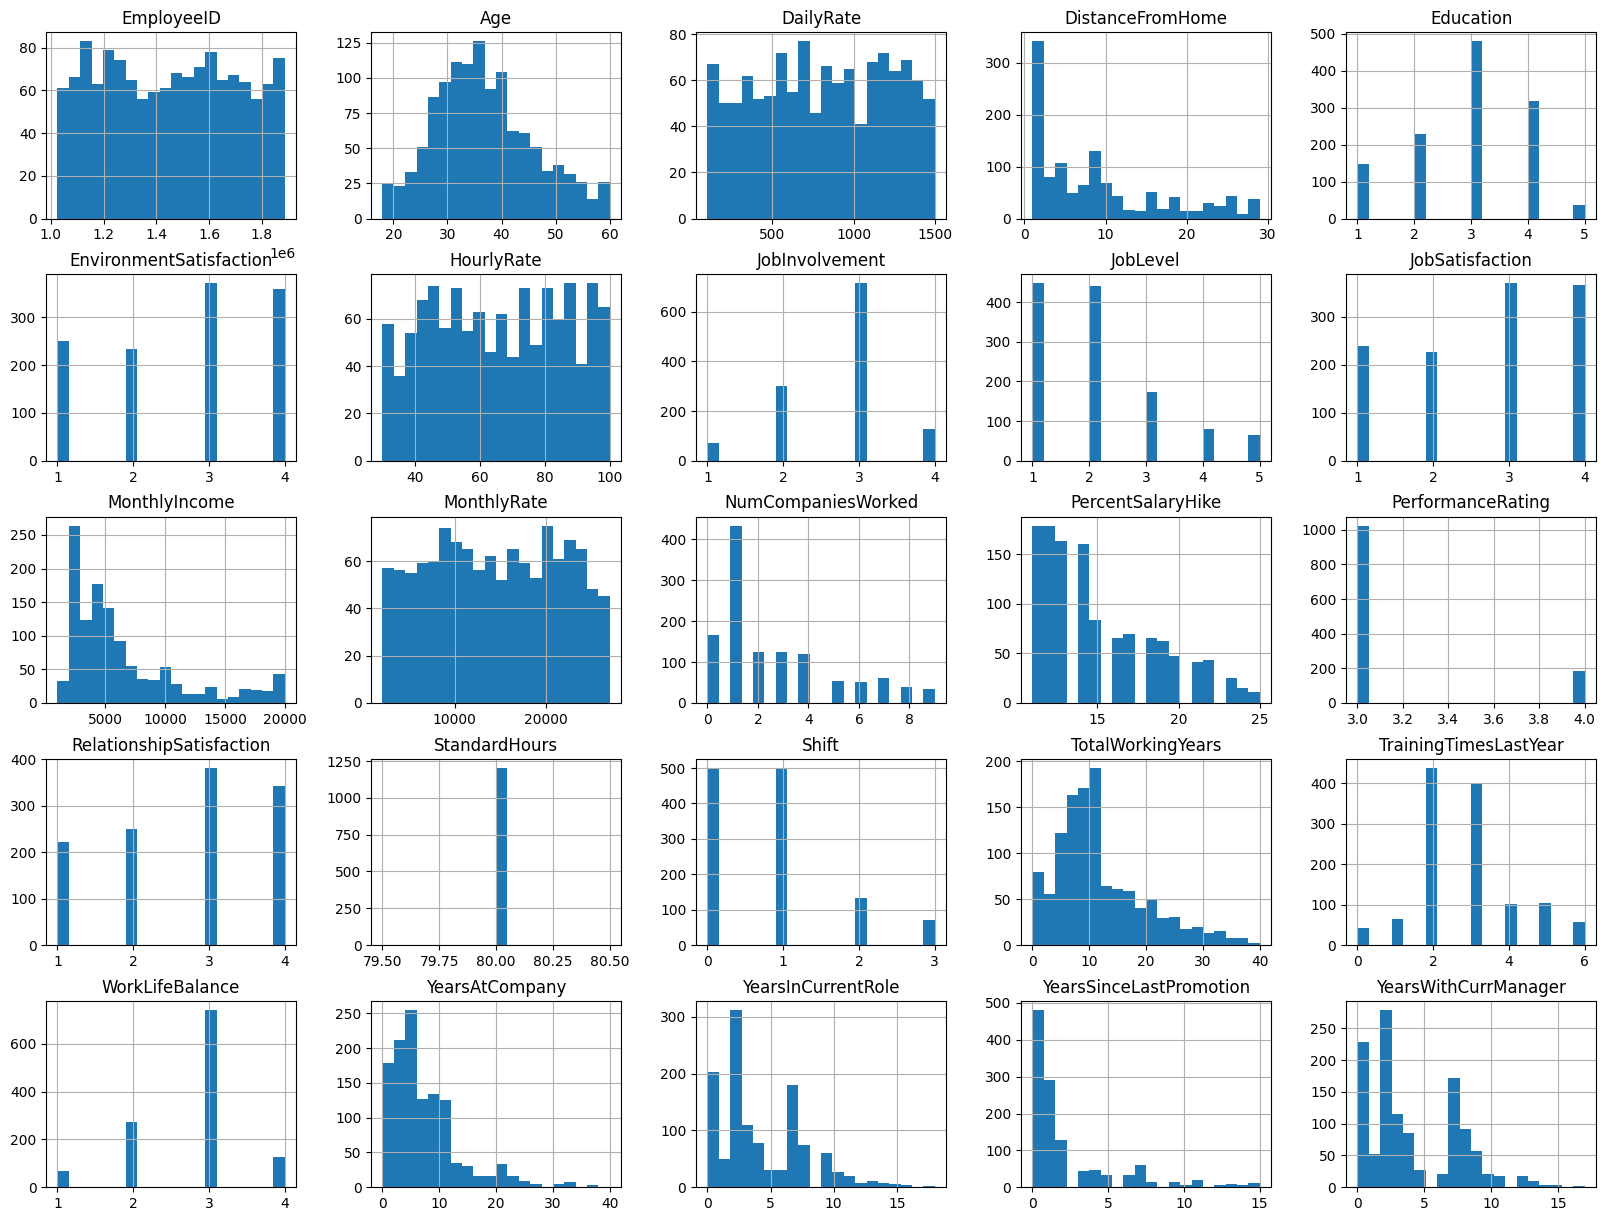

In [4]:
from matplotlib import pyplot as plt

traindata.hist(bins=20, figsize=(20,15))
plt.show()

Quite a few columns are skewed. We need to note them down for later. Also, `StandardHours` has a single value throughout all the rows. We will drop this column later on.

Next, for drawing boxplots, we need to provide a list of numeric columns. This can be done by filter to columns with types of `int64` or `float64`. Now, you can see the importance of having columns loaded in to their correct types.

Another note is that "ID" columns are usually not of interests. In this case, keeping `EmployeeID` will make the boxplots very difficut to look at, so I will remove it from the list.

In [5]:
num_cols = [column for column in attr.columns if (traindata[column].dtypes == np.int64) or (traindata[column].dtypes == np.float64)]
num_cols.remove('EmployeeID')
num_cols

['Age',
 'DailyRate',
 'DistanceFromHome',
 'Education',
 'EnvironmentSatisfaction',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StandardHours',
 'Shift',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager']

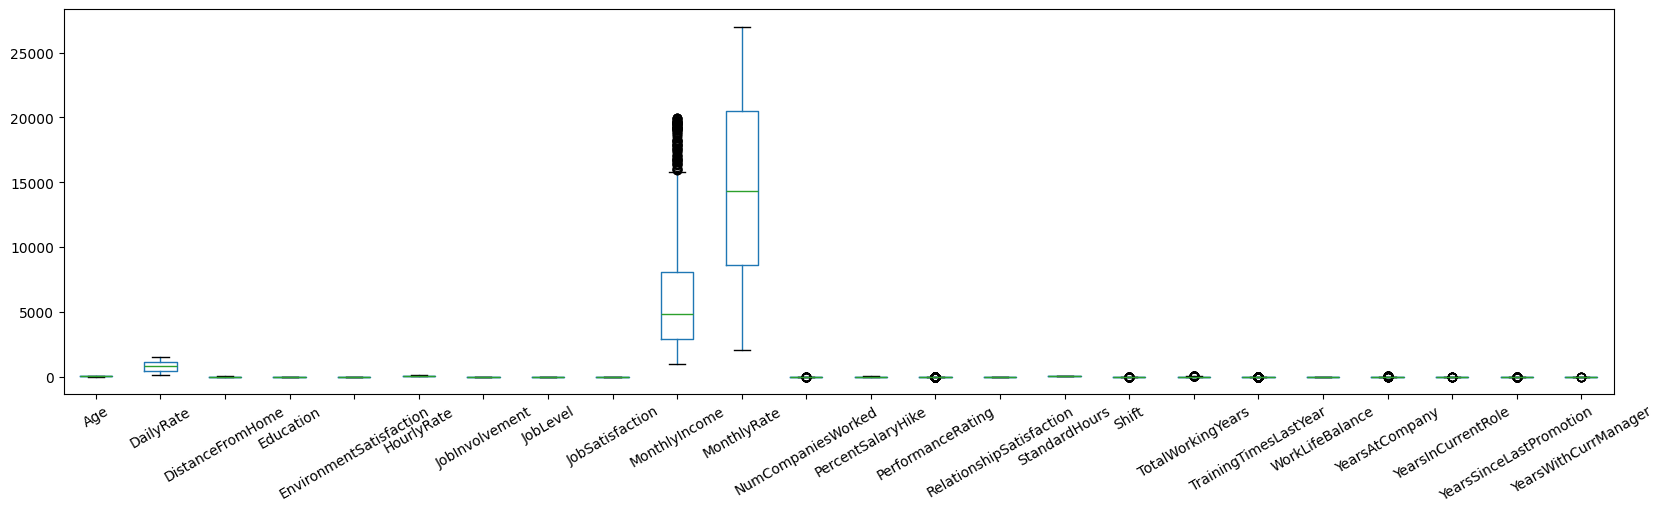

In [6]:
traindata[num_cols].boxplot(grid=False, figsize=(20,5), rot=30)
plt.show()

With a boxplot, we can clearly see that the numeric columns have very different ranges. This will need to be addressed in preprocessing with a process called **standardization**.

Finally, for categorical columns, we can filter all that has `dtypes` of `object`

In [7]:
cat_cols = [column for column in traindata.columns if traindata[column].dtypes == object]
cat_cols

['Attrition',
 'BusinessTravel',
 'Department',
 'EducationField',
 'Gender',
 'JobRole',
 'MaritalStatus',
 'Over18',
 'OverTime']

Then draw a bar chart for each column

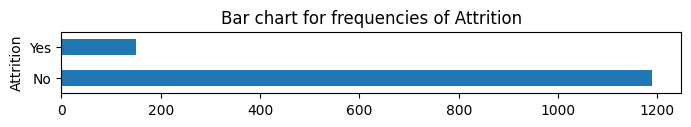

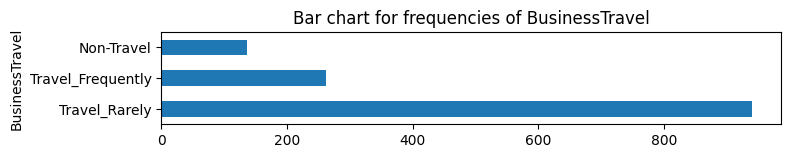

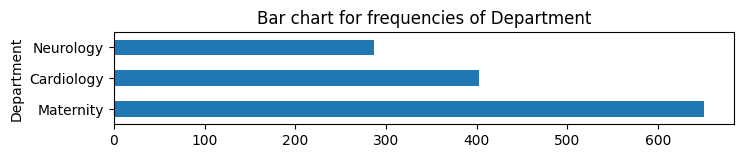

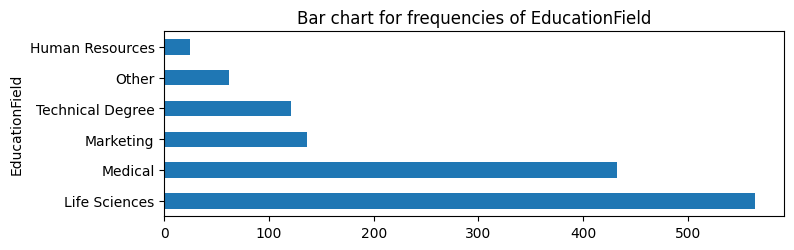

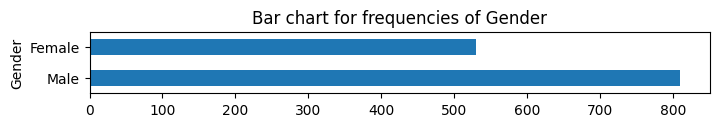

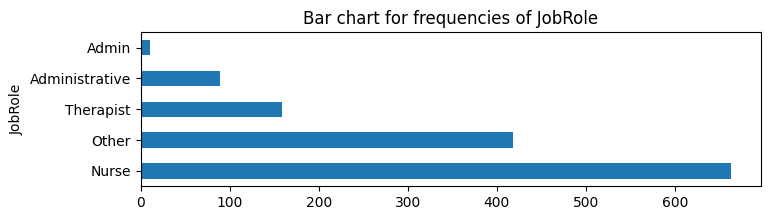

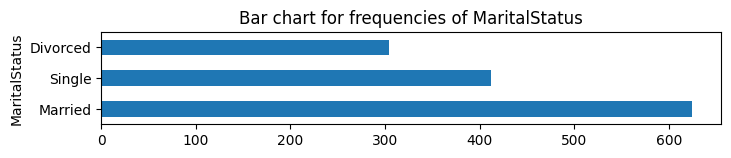

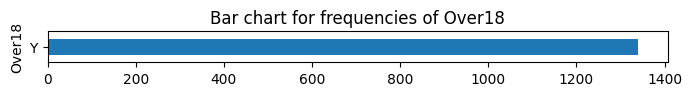

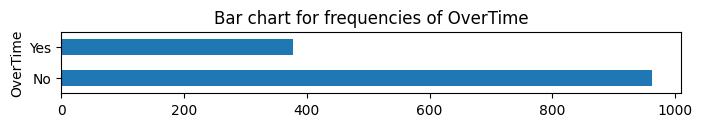

In [8]:
for col in cat_cols:
    freq_table = traindata[col].value_counts()
    plt.figure(figsize = (8,len(freq_table)*0.4)) #a bit formatting so that chart look better
    freq_table.plot.barh(title='Bar chart for frequencies of ' + col)
    plt.show()
    print()

Most columns are okay except for `Over18` which has a single value. So, we will remove `Over18` in preprocessing.

# Preprocessing

For preprocessing, we will use a very powerful tool that is called a **pipeline** that comes with `scikit-learn`. A pipeline allows us to define a series of transformation on data that simplifies this step by magnitudes. We will spend more times discussing pipelines in the next module.

In this project, the data will be transformed as follows:
- Symmetric numeric columns: imputation of missing values --> standardization
- Skewed numeric columns: imputation --> log transformation --> standardization
- Categorical columns: one hot encoder

As so, we need to list the columns for each type of transformation. Here, any columns that are not listed will be dropped from the processed data. Therefore, we will not list `EmployeeID` and `Over18`.

**Very Important: The target should not be included in any of the input lists.**

In [9]:
num_cols = ['Age', 'DailyRate', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement',
            'JobLevel', 'JobSatisfaction',  'MonthlyRate',  'PerformanceRating', 'RelationshipSatisfaction',
            'StandardHours', 'Shift', 'TrainingTimesLastYear', 'WorkLifeBalance']                                             #this list is for symmetric numeric columns
log_cols = ['DistanceFromHome', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike',
            'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']   #this list is for skewed numeric columns
cat_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']               #this list for the class columns
target = 'Attrition'                                                                                                          #this is the name of the target

In [10]:
#processing pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np

num_pipeline = Pipeline([                           #now we need a small pipeline for numeric columns since it has two steps
    ('impute', SimpleImputer(strategy='median')),   #this step will impute missing values using column medians
    ('standardize', StandardScaler())               #this step will scale all numeric columns
])

def log_transformation(x):
    return np.log(x+0.1)

log_pipeline = Pipeline([                                        #now we need a small pipeline for numeric columns since it has two steps
    ('impute', SimpleImputer(strategy='median')),                #this step will impute missing values using column medians
    ('log transform', FunctionTransformer(log_transformation)), #this include a log transformation into the pipeline
    ('standardize', StandardScaler())                            #this step will scale all numeric columns
])

processing_pipeline = ColumnTransformer([                                                      #this transformer merges the processed numeric columns and class columns
    ('numeric', num_pipeline, num_cols),                                                       #numeric columns
    ('log', log_pipeline, log_cols),                                                           #log columns
    ('class', OneHotEncoder(max_categories=5, handle_unknown='infrequent_if_exist'), cat_cols) #encoder to transform class columns to numeric, this will automatically handle missing data
  ])

In [11]:
processing_pipeline

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('standardize',
                                                  StandardScaler())]),
                                 ['Age', 'DailyRate', 'Education',
                                  'EnvironmentSatisfaction', 'HourlyRate',
                                  'JobInvolvement', 'JobLevel',
                                  'JobSatisfaction', 'MonthlyRate',
                                  'PerformanceRating',
                                  'RelationshipSatisfaction', 'StandardHours',
                                  'Shift', 'TrainingTi...
                                 ['DistanceFromHome', 'MonthlyIncome',
                                  'NumCompaniesWorked', 'PercentSalaryHike',
                                  'TotalWorkingYears', 'YearsAtCompany',
                                  'YearsInCurrentRole',
                                  'YearsSinceLastPromotion',
                                  'YearsWithCurrManager']),
                                ('class',
                                 OneHotEncoder(handle_unknown='infrequent_if_exist',
                                               max_categories=5),
                                 ['BusinessTravel', 'Department',
                                  'EducationField', 'Gender', 'JobRole',
                                  'MaritalStatus', 'OverTime'])])

`preprocessing_pipeline` is the final product of the preprocessing phase. Note that this is a pipeline object, not the actual data. Next, we will combine a model to the pipeline.

## Modeling

As the target is a class column, this is a classification problem. We will try several different models to pick a good one

- Logistic regression
- Decision tree
- Random Forest

We will discuss all models later on, so don't worry if you are not familiar with them right now.

So how do we compare the models? In classification problems like this, we will use accuracy rate, which essentially means how much of the data is preditected with the correct labels.

Now we can try different models. SKLearn is a very easy package to learn. All model pipeline will have the below functions:
- `fit()`: fit a model on the given data (and label, if applicable). Also mean training the model
- `predict()`: predict the label of the given data using the fitted model

The usual process is to first, train the model pipeline with `fit()`. Then, we make predictions with `predict()` and evaluate the results.

Note that for all models below, we are still not using testing data

<h4>Logistic Regression</h4>

In [12]:
from sklearn.linear_model import LogisticRegression                                                #This model user trained data.

logistic_pipeline = Pipeline([
    ('processing',processing_pipeline),
    ('modeling',LogisticRegression())
])
# given all features you try to predict(with know attrition) -> attrition
logistic_pipeline.fit(traindata, traindata[target])

Pipeline(steps=[('processing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardize',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyRate',
                                                   'PerformanceRating',
                                                   'RelationshipSatisfaction',
                                                   'Stan...
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'TotalWorkingYears',
                                                   'YearsAtCompany',
                                                   'YearsInCurrentRole',
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager']),
                                                 ('class',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                max_categories=5),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('modeling', LogisticRegression())])

In [13]:
logistic_pred = logistic_pipeline.predict(traindata)

print(logistic_pred)

['No' 'No' 'No' ... 'No' 'Yes' 'No']


In [14]:
logistic_pred = logistic_pipeline.predict(traindata)

from sklearn.metrics import accuracy_score
accuracy_score(traindata[target], logistic_pred)

0.9440298507462687

In [15]:
logistic_pred = logistic_pipeline.predict(testdata)
accuracy_score(testdata[target], logistic_pred)

0.9285714285714286

<h4>Decision Tree</h4>

In [16]:
from sklearn.tree import DecisionTreeClassifier

tree_pipeline = Pipeline([
    ('processing',processing_pipeline),
    ('modeling',DecisionTreeClassifier())
])

tree_pipeline.fit(traindata, traindata[target])

Pipeline(steps=[('processing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardize',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyRate',
                                                   'PerformanceRating',
                                                   'RelationshipSatisfaction',
                                                   'Stan...
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'TotalWorkingYears',
                                                   'YearsAtCompany',
                                                   'YearsInCurrentRole',
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager']),
                                                 ('class',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                max_categories=5),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('modeling', DecisionTreeClassifier())])

In [17]:
tree_pred = tree_pipeline.predict(traindata)
accuracy_score(traindata[target], tree_pred)

1.0

An accuracy rate of 1.0 means that 100% of the data is predicted with the correct labels. This is a sign of potential problems.

While we do not usually do this, let us try this model on the test data

In [18]:
tree_pred_test = tree_pipeline.predict(testdata)
accuracy_score(testdata[target], tree_pred_test)

0.8898809523809523

As can be seen, the accuracy drops significantly. This is a clear sign of **overfitting**

<h4>Random Forest</h4>

In [19]:
from sklearn.ensemble import RandomForestClassifier

forest_pipeline = Pipeline([
    ('processing',processing_pipeline),
    ('modeling',RandomForestClassifier())
])

forest_pipeline.fit(traindata, traindata[target])

Pipeline(steps=[('processing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardize',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyRate',
                                                   'PerformanceRating',
                                                   'RelationshipSatisfaction',
                                                   'Stan...
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'TotalWorkingYears',
                                                   'YearsAtCompany',
                                                   'YearsInCurrentRole',
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager']),
                                                 ('class',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                max_categories=5),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('modeling', RandomForestClassifier())])

In [20]:
forest_pred = forest_pipeline.predict(traindata)
accuracy_score(traindata[target], forest_pred)

1.0

Similarly, this model seems to have issues. Again, we should not do it here, but let us peak into this model performance on the test data.

In [21]:
forest_pred_test = forest_pipeline.predict(testdata)
accuracy_score(testdata[target], forest_pred_test)

0.9077380952380952

While not severe like decision tree, the testing performance of the forest model still a lot compared to in the training data. This model is also overfitting.

### Finetuning Models

The three models we have just trained are only with their default settings which are not optimal most of the times. After choosing your models, another very important step is to <b>finetune</b> them, which essentially means to search for an optimal set of settings so that our models are at their best performance.



#### Tuning Logistic Regression

Logistic regression has a hyperparamter `C` that controls how strictly the model is "constrained". We will perform finetuning for this parameter.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logistic = LogisticRegression(max_iter=10000)
param_grid = [{'C': [0.001, 0.01, 0.1, 1, 10, 100]}]
grid_search = GridSearchCV(logistic, param_grid, cv=5, scoring='accuracy', return_train_score=True)

logistic_pipeline = Pipeline([
    ('processing', processing_pipeline),
    ('modeling', grid_search)
])

logistic_pipeline.fit(traindata, traindata[target])

Pipeline(steps=[('processing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardize',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyRate',
                                                   'PerformanceRating',
                                                   'RelationshipSatisfaction',
                                                   'Stan...
                                                   'YearsWithCurrManager']),
                                                 ('class',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                max_categories=5),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('modeling',
                 GridSearchCV(cv=5,
                              estimator=LogisticRegression(max_iter=10000),
                              param_grid=[{'C': [0.001, 0.01, 0.1, 1, 10,
                                                 100]}],
                              return_train_score=True, scoring='accuracy'))])

In [ ]:
logistic_pred = logistic_pipeline.predict(traindata)
accuracy_score(traindata[target], logistic_pred)

#### Tuning Decision Tree

We will finetune four parameters for decision tree.

In [25]:
from sklearn.tree import DecisionTreeClassifier

param_grid = [{
    'max_depth': [2, 3, 4, 5],
    'max_features' : [5, 10, 15, 20],
    'min_samples_split' : [25, 50, 100, 200],
    'min_samples_leaf' : [25, 50, 100, 200]
}]

tree = DecisionTreeClassifier()

grid_search = GridSearchCV(tree, param_grid, cv=5, scoring='accuracy', return_train_score=True)

tree_pipeline = Pipeline([
    ('processing', processing_pipeline),
    ('modeling tree', grid_search)
])

tree_pipeline.fit(traindata, traindata[target])

Pipeline(steps=[('processing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardize',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyRate',
                                                   'PerformanceRating',
                                                   'RelationshipSatisfaction',
                                                   'Stan...
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('modeling tree',
                 GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
                              param_grid=[{'max_depth': [2, 3, 4, 5],
                                           'max_features': [5, 10, 15, 20],
                                           'min_samples_leaf': [25, 50, 100,
                                                                200],
                                           'min_samples_split': [25, 50, 100,
                                                                 200]}],
                              return_train_score=True, scoring='accuracy'))])

In [23]:
tree_pred = tree_pipeline.predict(traindata)
accuracy_score(traindata[target], tree_pred)

1.0

#### Tuning Random Forest

Finetuning random forests is similar to trees, we just have one more parameter which is the number of trees in the forest. This code will take a bit of time to run though.

In [24]:
from sklearn.ensemble import RandomForestClassifier

param_grid = [{
    'max_depth': [2, 3, 4, 5],
    'max_features' : [5, 10, 15, 20],
    'min_samples_split' : [25, 50, 100, 200],
    'min_samples_leaf' : [25, 50, 100, 200],
    'n_estimators': [5, 10, 20, 50]
}]

forest = RandomForestClassifier()

grid_search = GridSearchCV(forest, param_grid, cv=5, scoring='accuracy', return_train_score=True)

forest_pipeline = Pipeline([
    ('processing', processing_pipeline),
    ('modeling forest', grid_search)
])

forest_pipeline.fit(traindata, traindata[target])

Pipeline(steps=[('processing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardize',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyRate',
                                                   'PerformanceRating',
                                                   'RelationshipSatisfaction',
                                                   'Stan...
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('modeling forest',
                 GridSearchCV(cv=5, estimator=RandomForestClassifier(),
                              param_grid=[{'max_depth': [2, 3, 4, 5],
                                           'max_features': [5, 10, 15, 20],
                                           'min_samples_leaf': [25, 50, 100,
                                                                200],
                                           'min_samples_split': [25, 50, 100,
                                                                 200],
                                           'n_estimators': [5, 10, 20, 50]}],
                              return_train_score=True, scoring='accuracy'))])

In [26]:
forest_pred = forest_pipeline.predict(traindata)
accuracy_score(traindata[target], forest_pred)

0.9156716417910448

## Applying Trained Models on Test Data

With the models trained, applying them is very straightforward. We make predictions for the `testdata`, then evaluate using `accuracy_score()`.

In [27]:
logistic_pred_test = logistic_pipeline.predict(testdata)
accuracy_score(testdata[target], logistic_pred_test)

0.9196428571428571

In [28]:
tree_pred_test = tree_pipeline.predict(testdata)
accuracy_score(testdata[target], tree_pred_test)

0.8928571428571429

In [29]:
forest_pred_test = forest_pipeline.predict(testdata)
accuracy_score(testdata[target], forest_pred_test)

0.8928571428571429

After finetuning, we can see that all models have very similar performances on the test data. If you want the absolute best among the three, you can use Logistic regression. However, the differences are small enough, so any models will work just fine.